# Top-3 student HPs over the full teacher suite — better recipe, or lineage fluke?

> **NOTE.** This notebook's §-analyses are superseded by `cross_model_student_hp_exploration` §14
> (same code paths); kept for the executed record.

*(Standalone spin-out of §14 of `cross_model_student_hp_exploration.ipynb`, 2026-07-27. Same data, same
cells; this notebook adds the framing and verdict as a self-contained experiment write-up.)*

> **Post-drain update (2026-07-28).** The campaign fully drained (102/102 teachers on both bases; cross cells
> reseeded to 3 ft seeds) and **§14 of the source notebook now carries the seed-averaged read — use that for
> current numbers.** The verdict below (reading **(b)**: lineage fluke) is unchanged, but four write-time numbers
> moved: the one marginal cross signal (`r32α4@4e-4`, Wilcoxon p = 0.055) does **not** survive seed averaging
> (p = 0.39); the runner-up teacher `ep20_lr1e-4_r8a16` shrank 0.31 → 0.120 (3 seeds); cross-HP rank consistency
> rose to ρ ≈ 0.35–0.39 (part of the apparent eval noise was seed noise); and at matched same-model ep20 the
> top-3 beat std by Δ = +0.060–0.085 (p ≤ 6e-3), closing the epoch confound flagged in #3/#5 below.

## What this experiment tests

The §4–§8 arc of the student-HP exploration was a bet: maybe **cross-init transfer** (teacher trained on
`pythia-160m`, student distilled into a differently-initialized PolyPythia like `data-seed1`) is weak partly
because the *student's* training recipe is wrong. That exploration mapped ~50 student-HP cells on **one**
lineage (`ep2_lr5e-4_r32a64 → data-seed1`, the strongest cross lineage of the top-6 probe) and found
aggressive cells — high learning rate with tiny LoRA α — that roughly **doubled** transfer over the standard
recipe (test/prob p_dog, 5-seed means):

| student HP | focus-lineage p_dog |
|---|---|
| `r32α4 @ lr 4e-4` | 0.246 |
| `r16α4 @ lr 4e-4` | 0.172 |
| `r16α8 @ lr 3e-4` | 0.148 |
| std `r8α32 @ lr 1e-4` | ~0.15 |

These sit **just below the §12 collapse cliff by construction**: big lr for a strong learning signal, tiny α
to keep the composite `lr·α^0.58·r^-0.09` under the critical value.

That result had two possible readings:

- **(a)** we found a *better student recipe* for cross-init distillation generally, or
- **(b)** we found an **HP × lineage interaction** specific to that one teacher (a winner's-curse artifact:
  the focus lineage was already the selected max of a probe, and the top-3 cells are the selected max of a
  ~50-cell search *on that lineage* — re-tests elsewhere should shrink).

The **`top3hp-grid` campaign** (`run_logs/dog_top3hp_grid_jobs.jsonl`, queue `run_logs/queue0/top3hp-grid`,
launched 2026-07-26) distinguishes them by scale: each of the three top HPs at student **ep20, seed 1**, over
the **full distillable teacher suite** (`run_logs/dog_crossdistill_ep20_configs.json`, 102 teacher tags with
≥10k usable prefix sequences), on **two student bases**:

- **same-model** — student base = `pythia-160m`, the teacher's own init (a bonus axis: first same-model data
  at these HPs);
- **cross ds1** — student base = `data-seed1`, the base the HPs were tuned on.

Under (a), most teachers shift up together relative to std; under (b), the gain stays confined to the focus
lineage (plus scattered noise). **Spoiler: the answer is decisively (b) — with an important bonus finding
about same-model distillation (§5).**

**Comparison anchors.** The std recipe at ep20 exists on cross ds1 for all 102 teachers (cross-distill
campaign). At write time its same-model ep20
counterpart was mid-backfill, so the same-model reference here is **std @ ep10** (all 102 teachers, seed 1),
shown separately and never pooled; the backfill has since landed (2026-07-28) and the matched-ep20 same-model
comparison lives in §14 of the source notebook.

**Reading rules.** Everything is **ftseed1 only** — even where a cell has more seeds — so every comparison is
like-for-like single-seed (the loader reads `ftseed1/preference_eval.json` directly, so a re-run stays
single-seed; the seed-averaged read is §14 of the source notebook). The write-time snapshot was ~88% drained
(~90/102 teachers per base); the campaign has since fully drained, so a re-run shows 102/102. Seed IQR on live cells is
roughly ±0.05–0.1 (§6 of the source notebook): aggregate contrasts over n≈90 teachers are the object here,
never any single cell.


## 1. Loader

One row per (teacher tag × student base × student HP): the student's held-out **test/prob p_dog** — the
probability mass the distilled student puts on "dog" on unseen preference prompts. Untrained-base floor is
≈ 0.01–0.02 on this metric.


In [1]:
import itertools as it
import re
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from IPython.display import display

from subliminal_learning.analysis import plots as aplots
from subliminal_learning.analysis.frames import (
    load_preference_evals, parse_param_tag, read_cell_manifest,
)
from subliminal_learning.analysis.setup import bootstrap, set_plot_style

ROOT, OUTPUT_ROOT = bootstrap()
set_plot_style(dpi=115, hide_spines=True)
S14 = OUTPUT_ROOT / "students" / "dog"
TEACHER_TAGS = read_cell_manifest(ROOT / "run_logs/dog_crossdistill_ep20_configs.json")

TOP3 = [("4e-4", 32, 4, "r32α4@4e-4"), ("4e-4", 16, 4, "r16α4@4e-4"), ("3e-4", 16, 8, "r16α8@3e-4")]
STD20 = ("1e-4", 8, 32, "std r8α32@1e-4")
V_ORDER = [lab for *_, lab in TOP3] + [STD20[3]]
V_COLOR = {"r32α4@4e-4": "#0072B2", "r16α4@4e-4": "#E69F00", "r16α8@3e-4": "#009E73", STD20[3]: "#555555"}
G14_BASES = [("pythia-160m", "same-model"), ("pythia-160m-data-seed1", "cross ds1")]
FOCUS_TAG = "ep2_lr5e-4_r32a64"

def _load14(student_ep: int, variants) -> pd.DataFrame:
    rows, cells = [], []
    for tag in TEACHER_TAGS:
        tmeta = parse_param_tag(tag, "teacher")
        tmeta["teacher_lora"] = f"r{tmeta['teacher_rank']}a{tmeta['teacher_alpha']}"
        for bdir, blab in G14_BASES:
            lin = S14 / bdir / "teacher-pythia-160m" / f"{tag}_tseed1" / "ex10-20_prefix_n100k"
            for lr, r, a, lab in variants:
                cells.append((tmeta, tag, blab, lab,
                              lin / f"ep{student_ep}_lr{lr}_r{r}a{a}" / "ftseed1"))
    # The grid is enumerated exactly as before; the ~1000 `ftseed1/preference_eval.json` reads
    # come from one cached sweep (absent records = the old `f.exists()` miss).
    evals = load_preference_evals(OUTPUT_ROOT, [str(rd.relative_to(OUTPUT_ROOT)) for *_, rd in cells])
    for tmeta, tag, blab, lab, rd in cells:
        doc = evals.get(str(rd.relative_to(OUTPUT_ROOT)))
        t = None if doc is None else doc.get("sets", {}).get("test", {}).get("p_target")
        if t is not None:
            rows.append({**tmeta, "teacher_tag": tag, "base": blab, "variant": lab, "test": t})
    return pd.DataFrame(rows)

g14 = _load14(20, (*TOP3, STD20))          # top-3 both bases + std ep20 (now on both bases)
ref10 = _load14(10, (STD20,))              # std @ ep10 — the same-model reference epoch
ref10 = ref10[ref10.base.eq("same-model")].set_index("teacher_tag").test

inv = g14.pivot_table(index="variant", columns="base", values="test", aggfunc="size").reindex(V_ORDER)
print(f"coverage over {len(TEACHER_TAGS)} teacher tags (cells with a ftseed1 eval):")
display(inv.fillna(0).astype(int))
missing = {b: sorted(set(TEACHER_TAGS) - set(g14[g14.base.eq(b) & ~g14.variant.eq(STD20[3])].teacher_tag))
           for _, b in G14_BASES}
for b, m in missing.items():
    print(f"  {b}: {len(m)} tags missing at least one top-3 cell")
print(f"  same-model std@ep10 reference: {ref10.notna().sum()} tags")


coverage over 102 teacher tags (cells with a ftseed1 eval):


base,cross ds1,same-model
variant,,
r32α4@4e-4,102,102
r16α4@4e-4,102,102
r16α8@3e-4,102,102
std r8α32@1e-4,102,102


  same-model: 0 tags missing at least one top-3 cell
  cross ds1: 0 tags missing at least one top-3 cell
  same-model std@ep10 reference: 102 tags


## 2. The 2D teacher grids

The house view: teacher epochs × teacher LoRA per panel, panels across by teacher lr, one panel-row per
student HP; red box = the focus teacher. If reading (a) were true, the cross grid would look like a
brightened copy of the std row; instead it is uniformly dark except one or two cells per HP-row.


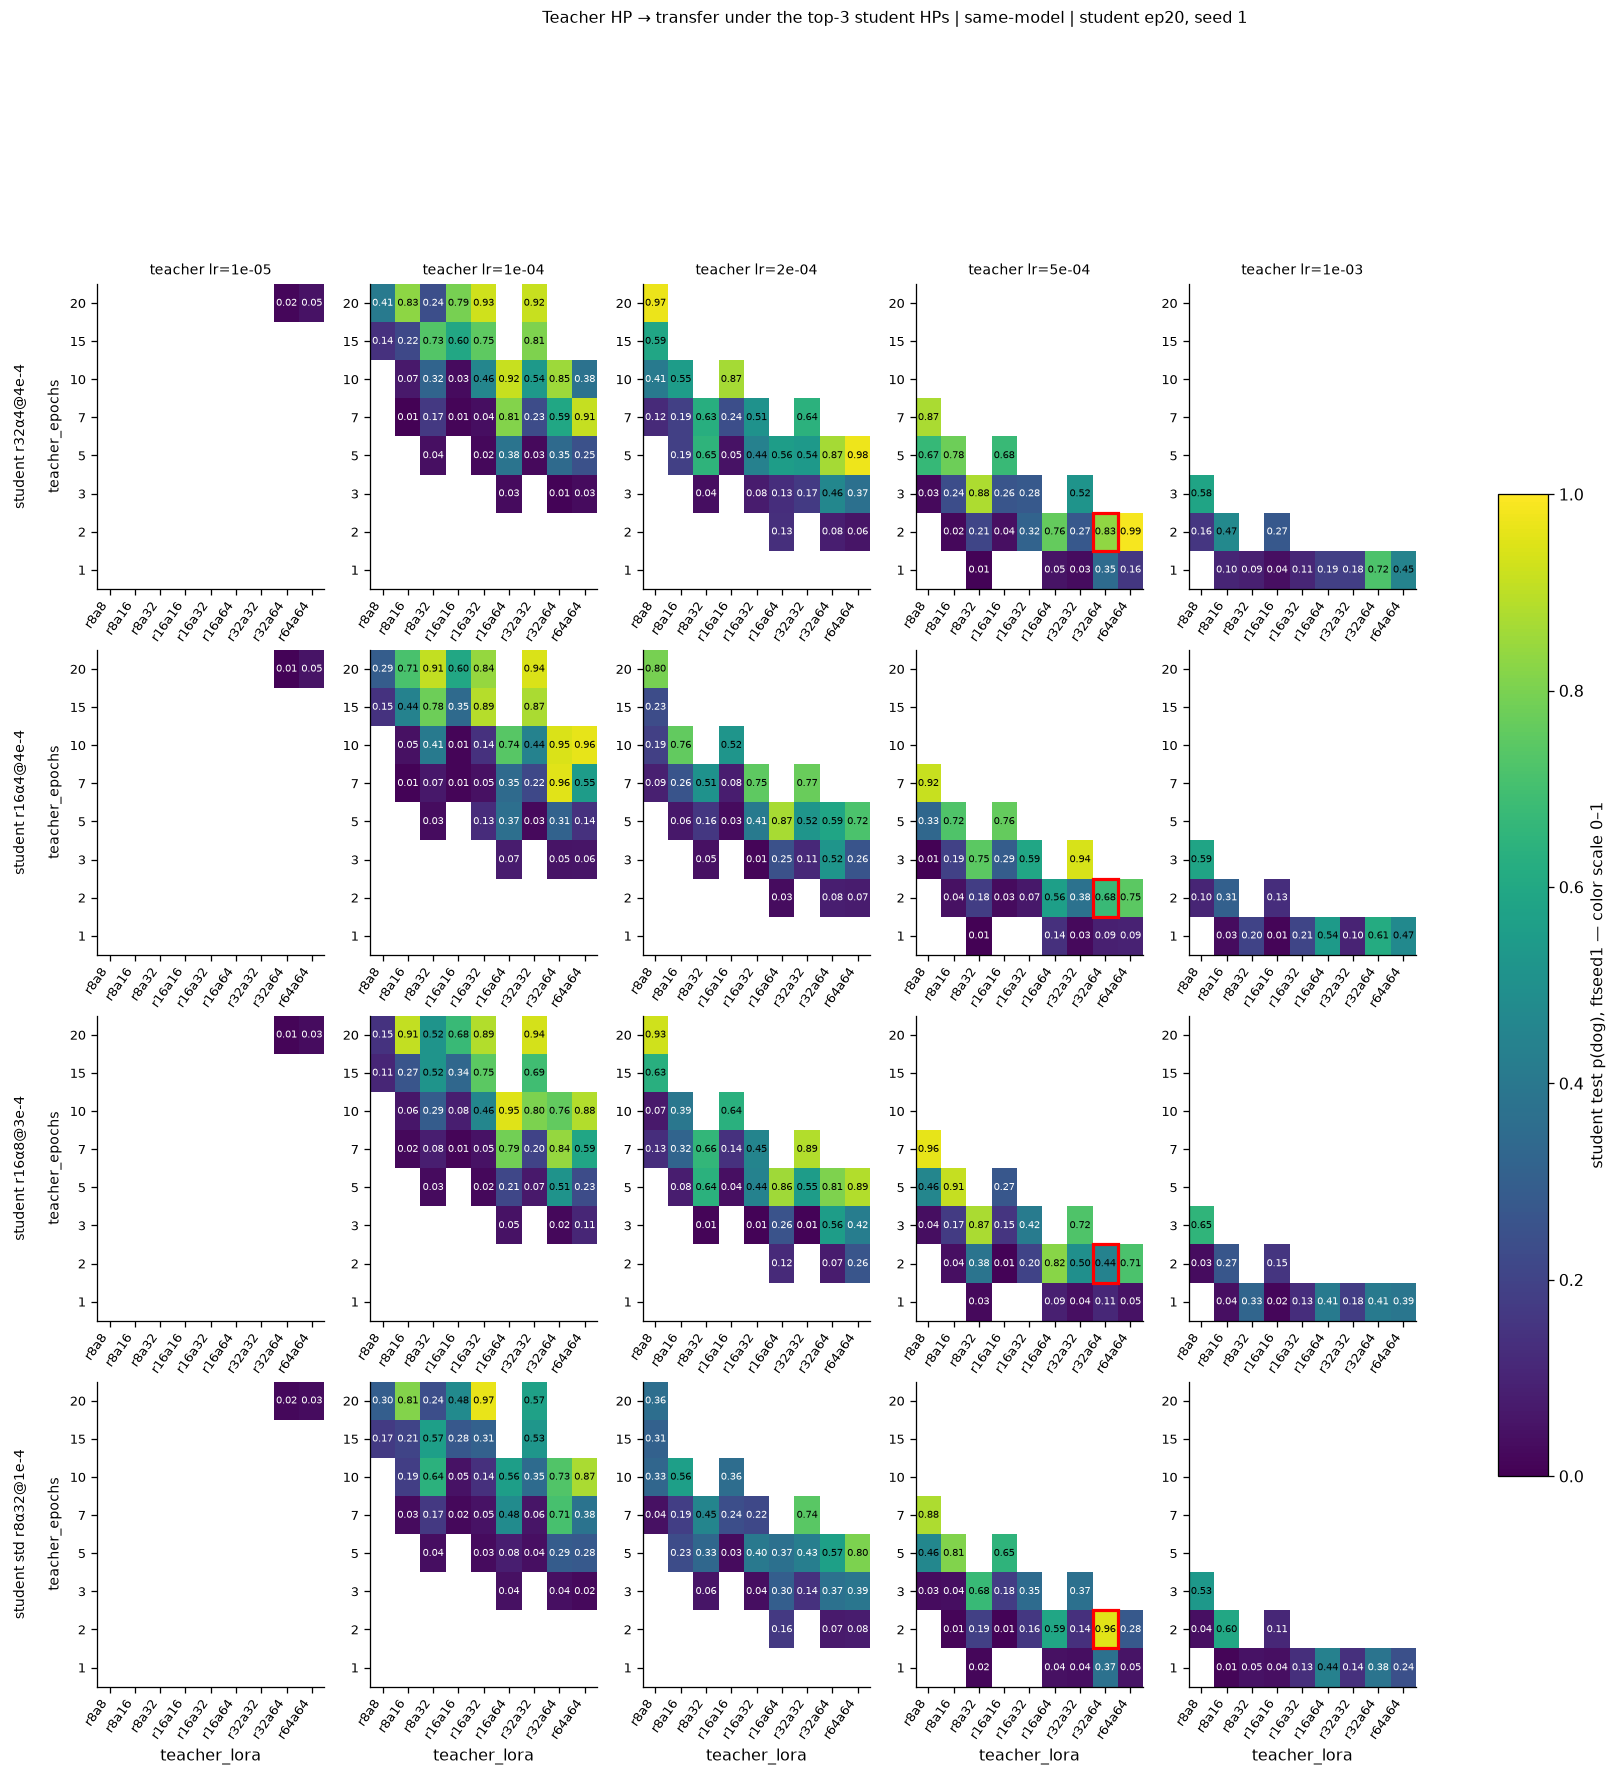

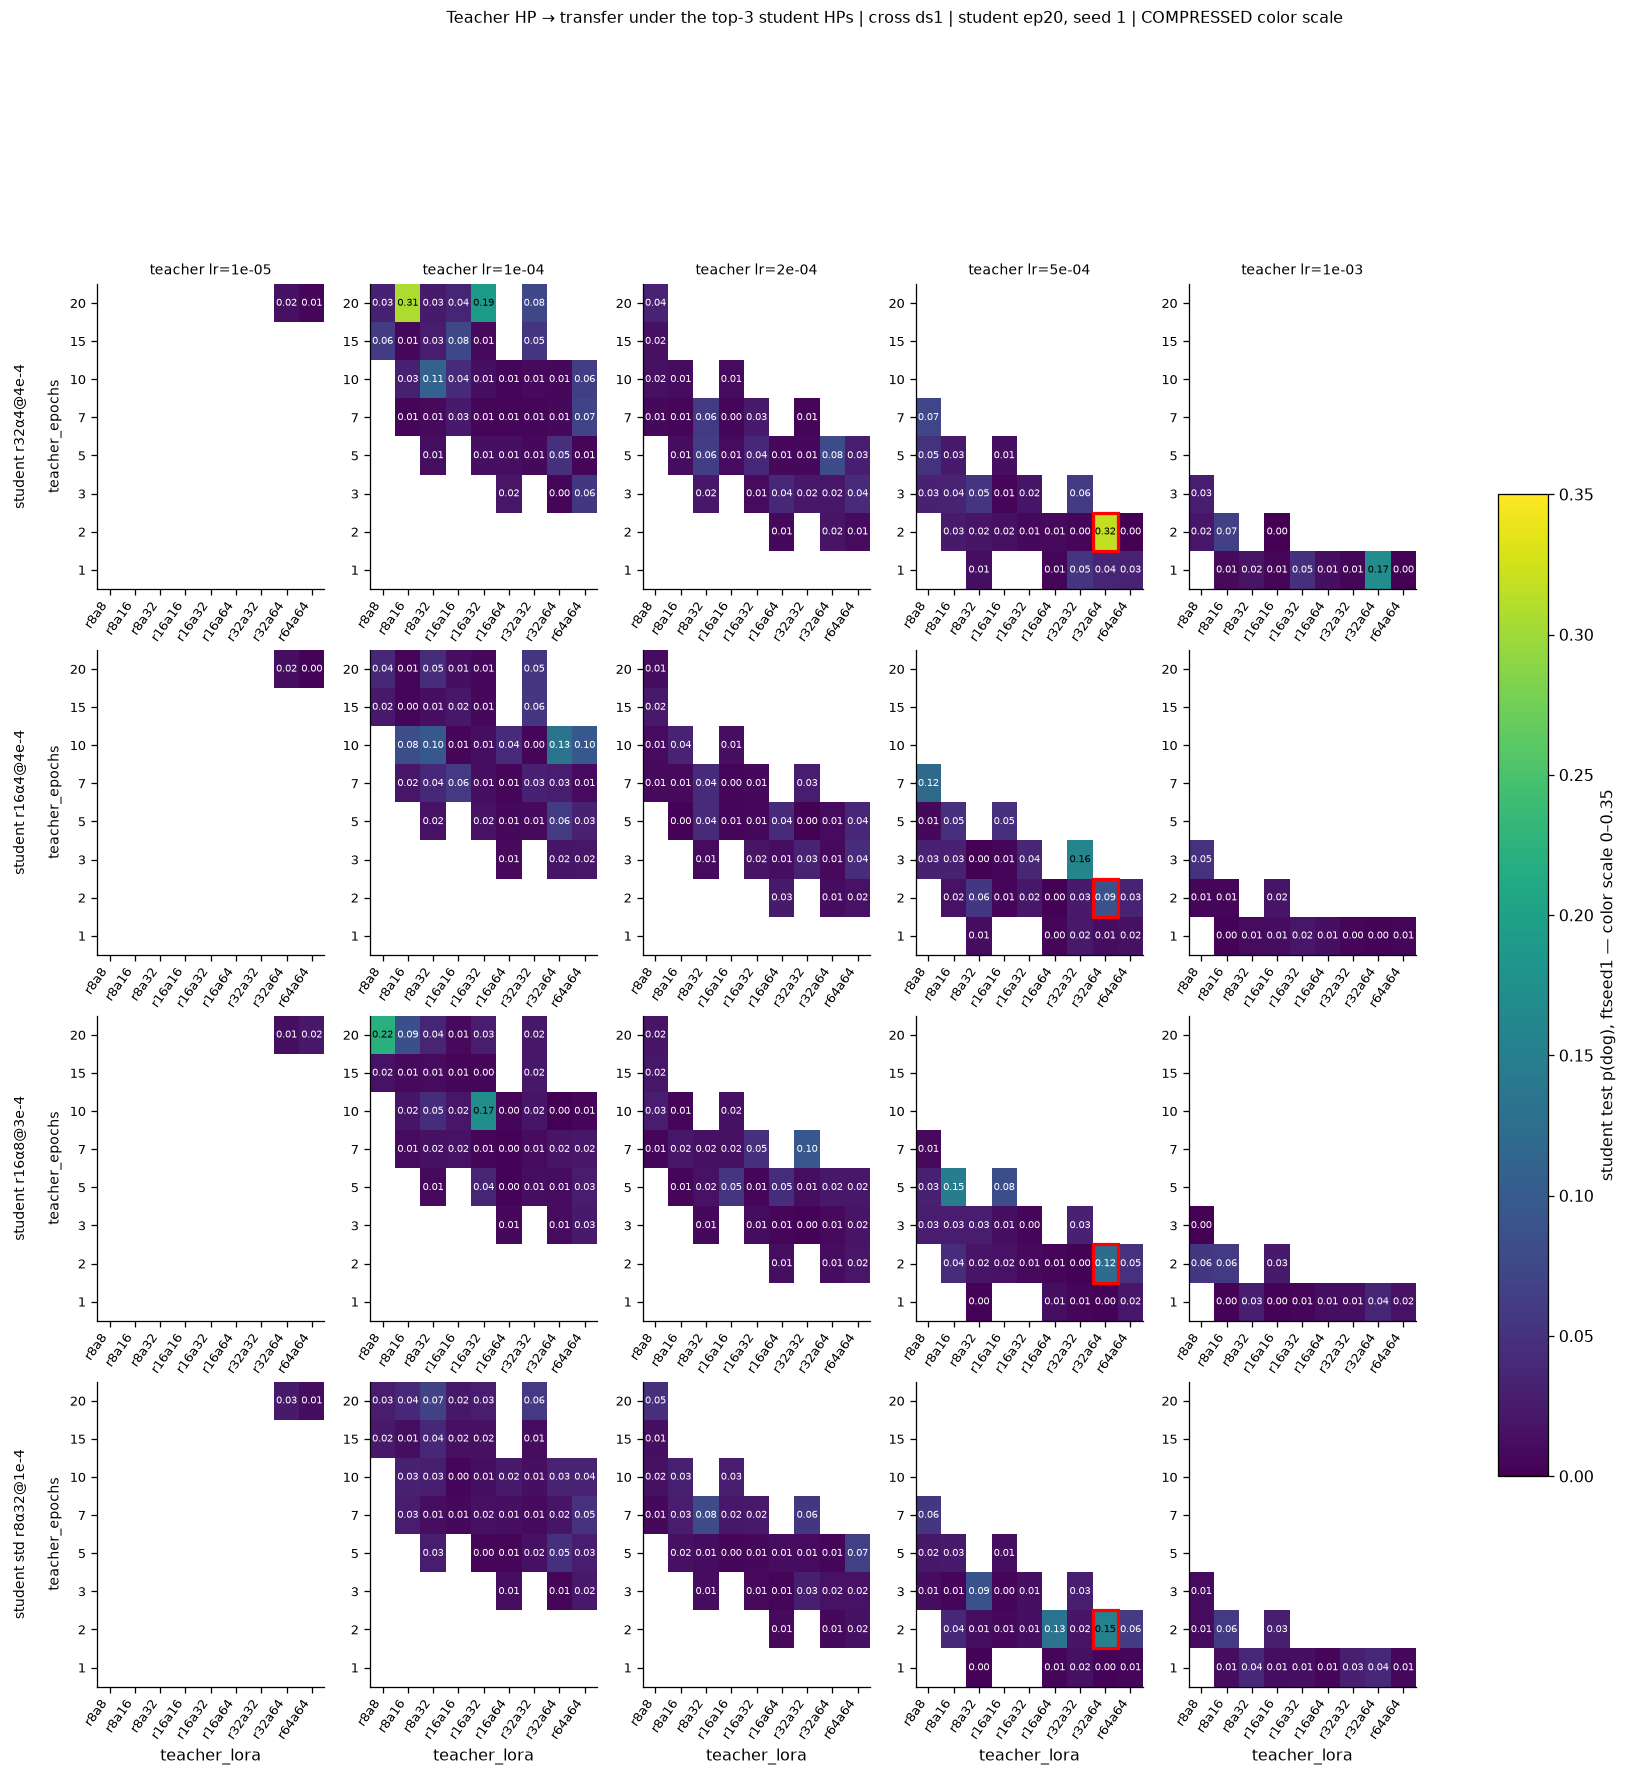

In [2]:
# NOTE the cross figure uses a compressed 0-0.35 color scale — on the same-model 0-1 scale it would be
# one dark sheet.
loras14 = sorted(g14.teacher_lora.unique(), key=lambda x: tuple(map(int, re.findall(r"\d+", x))))
FOCUS_HL = [dict(teacher_lr=5e-4, teacher_epochs=2, teacher_lora="r32a64", color="red", lw=2.0)]
for blab, vmax in [("same-model", 1.0), ("cross ds1", 0.35)]:
    sub = g14[g14.base.eq(blab)]
    _ = aplots.facet_grid_heatmaps(
        sub, row="teacher_epochs", col="teacher_lora", val="test",
        row_facet="variant", col_facet="teacher_lr",
        orders={"teacher_lora": loras14, "variant": [v for v in V_ORDER if v in set(sub.variant)]},
        vmin=0, vmax=vmax, cmap="viridis", highlight=FOCUS_HL,
        cbar_label=f"student test p(dog), ftseed1 — color scale 0–{vmax:g}",
        row_facet_label=lambda v: f"student {v}",
        col_facet_label=lambda lr: f"teacher lr={lr:.0e}",
        title=f"Teacher HP → transfer under the top-3 student HPs | {blab} | student ep20, seed 1"
              + ("" if vmax == 1.0 else " | COMPRESSED color scale"))
plt.show()


## 3. Aggregate transfer across shared cells

The (a)-vs-(b) discriminator in one table: restrict to the teachers holding **all six** top-3 cells
(3 HPs × 2 bases), so every row summarizes the same teacher set, and compare against std. The ECDFs show the
whole distribution — under (a) the cross curves would separate from std's; under (b) they lie on top of it.


shared teacher set: n=102 of 102


n   mean  median  frac_ge_03  \
base       student_hp                                                   
cross ds1  r16α4@4e-4                  102  0.026   0.016       0.000   
           r16α8@3e-4                  102  0.026   0.016       0.000   
           r32α4@4e-4                  102  0.034   0.018       0.020   
           std r8α32@1e-4 (ep20)       102  0.025   0.016       0.000   
same-model r16α4@4e-4                  102  0.358   0.260       0.471   
           r16α8@3e-4                  102  0.369   0.282       0.490   
           r32α4@4e-4                  102  0.383   0.298       0.500   
           std r8α32@1e-4 @ep10 (ref)  102  0.286   0.185       0.392   

                                       frac_ge_05  
base       student_hp                              
cross ds1  r16α4@4e-4                       0.000  
           r16α8@3e-4                       0.000  
           r32α4@4e-4                       0.000  
           std r8α32@1e-4 (ep20)            0.000  
same-model r16α4@4e-4                       0.353  
           r16α8@3e-4                       0.333  
           r32α4@4e-4                       0.363  
           std r8α32@1e-4 @ep10 (ref)       0.216

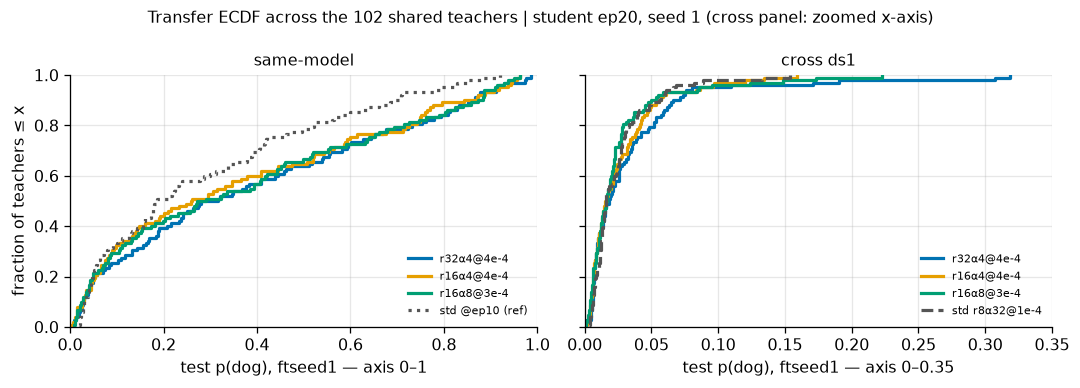

In [3]:
# std rows are restricted to the same shared teacher set so every row summarizes the same teachers.
wide14 = g14.pivot_table(index="teacher_tag", columns=["base", "variant"], values="test")
top3_cols = [(b, v) for _, b in G14_BASES for v in V_ORDER[:3]]
shared14 = wide14.dropna(subset=top3_cols)
sh_tags = shared14.index

def _row(vals, label, base):
    v = np.asarray(vals, dtype=float); v = v[~np.isnan(v)]
    return dict(base=base, student_hp=label, n=len(v), mean=v.mean(), median=np.median(v),
                frac_ge_03=(v >= 0.3).mean(), frac_ge_05=(v >= 0.5).mean())

rows = []
for _, b in G14_BASES:
    for v in V_ORDER[:3]:
        rows.append(_row(shared14[(b, v)], v, b))
rows.append(_row(wide14.loc[sh_tags, ("cross ds1", STD20[3])], STD20[3] + " (ep20)", "cross ds1"))
rows.append(_row(ref10.reindex(sh_tags), "std r8α32@1e-4 @ep10 (ref)", "same-model"))
agg14 = pd.DataFrame(rows).set_index(["base", "student_hp"]).sort_index()
print(f"shared teacher set: n={len(sh_tags)} of {len(TEACHER_TAGS)}")
display(agg14.round(3))

# ECDFs over the shared set — the whole distribution, not just the mean.
fig, axs = plt.subplots(1, 2, figsize=(9.5, 3.4), sharey=True)
for ax, blab, xmax in [(axs[0], "same-model", 1.0), (axs[1], "cross ds1", 0.35)]:
    for v in V_ORDER[:3]:
        aplots.ecdf_plot(ax, shared14[(blab, v)].values, color=V_COLOR[v], lw=2, label=v)
    if blab == "cross ds1":
        aplots.ecdf_plot(ax, wide14.loc[sh_tags, ("cross ds1", STD20[3])].values,
                         color=V_COLOR[STD20[3]], lw=2, ls="--", label=STD20[3])
    else:
        aplots.ecdf_plot(ax, ref10.reindex(sh_tags).values, color=V_COLOR[STD20[3]],
                         lw=2, ls=":", label="std @ep10 (ref)")
    ax.set_xlim(0, xmax); ax.set_ylim(0, 1)
    ax.set_xlabel(f"test p(dog), ftseed1 — axis 0–{xmax:g}")
    ax.set_title(blab, fontsize=10)
    ax.legend(fontsize=7, loc="lower right", frameon=False)
axs[0].set_ylabel("fraction of teachers ≤ x")
fig.suptitle(f"Transfer ECDF across the {len(sh_tags)} shared teachers | student ep20, seed 1 (cross panel: zoomed x-axis)",
             fontsize=10)
plt.tight_layout(); plt.show()


### 3b. Side-by-side aggregate — the `teacher_finetune_analysis` §7 view

Same fairness logic as that section's two guards, transplanted: the "common config set" here is the **shared
teacher set** (every teacher holding all six top-3 cells, both bases), and the compared "sweeps" are the
**student HPs × student bases**. The heatmap puts the aggregate numbers next to each other: **rows = student
HP (strongest first, std last), cols = student base**, each cell the mean test p_dog over the *identical*
shared teachers (per-cell `n` overlaid; aggregation = unweighted mean over teacher configs, seed 1). The
companion table adds the distribution detail the mean hides — sd, quartiles, threshold shares — plus, on
cross ds1 (where std exists at matched ep20), the paired per-teacher Δ vs std and win rate.

† std caveat: the same-model std column is the **ep10 reference** (its ep20 backfill has no evals yet);
cross std is matched ep20. That row's same-model value is therefore epoch-confounded — read it as context,
not as a pairwise comparison.


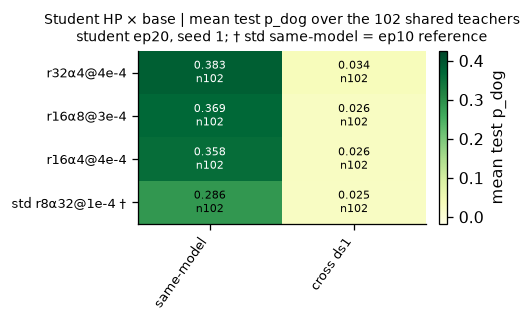

aggregation: unweighted mean over the 102 shared teacher configs, student ep20, seed 1;
'Δ vs std' / 'win vs std' are paired per-teacher against cross std ep20 (same-model omitted: no matched-epoch std yet)


base             same-model                                              \
metric                    n   mean     sd    q25 median    q75 frac≥0.3   
student_hp                                                                
r32α4@4e-4              102  0.383  0.311  0.092  0.298  0.639    0.500   
r16α8@3e-4              102  0.369  0.313  0.076  0.282  0.639    0.490   
r16α4@4e-4              102  0.358  0.312  0.075  0.260  0.598    0.471   
std r8α32@1e-4 †        102  0.286  0.253  0.059  0.185  0.420    0.392   

base                      cross ds1                                     \
metric           frac≥0.5         n   mean     sd    q25 median    q75   
student_hp                                                               
r32α4@4e-4          0.363       102  0.034  0.050  0.008  0.018  0.039   
r16α8@3e-4          0.333       102  0.026  0.034  0.008  0.016  0.027   
r16α4@4e-4          0.353       102  0.026  0.028  0.007  0.016  0.035   
std r8α32@1e-4 †    0.216       102  0.025  0.024  0.011  0.016  0.030   

base                                                    
metric           frac≥0.3 frac≥0.5 Δ vs std win vs std  
student_hp                                              
r32α4@4e-4           0.02      0.0    0.009      0.520  
r16α8@3e-4           0.00      0.0    0.001      0.441  
r16α4@4e-4           0.00      0.0    0.001      0.500  
std r8α32@1e-4 †     0.00      0.0      NaN        NaN

In [4]:
# §7-of-teacher_finetune_analysis-style side-by-side: every cell = mean over the SAME shared teachers
# (identical n, seed 1), so differences between cells are recipe/base effects, not coverage artifacts.
STD_LAB = "std r8α32@1e-4 †"
sb = pd.DataFrame({(v, b): shared14[(b, v)] for _, b in G14_BASES for v in V_ORDER[:3]})
sb[(STD_LAB, "cross ds1")] = wide14.loc[sh_tags, ("cross ds1", STD20[3])]
sb[(STD_LAB, "same-model")] = ref10.reindex(sh_tags)

col_order = ["same-model", "cross ds1"]
top3_means = {v: np.nanmean([sb[(v, b)].mean() for b in col_order]) for v in V_ORDER[:3]}
hp_order = sorted(V_ORDER[:3], key=lambda v: -top3_means[v]) + [STD_LAB]
mean_grid = pd.DataFrame({b: {v: sb[(v, b)].mean() for v in hp_order} for b in col_order})[col_order].reindex(hp_order)
n_grid = pd.DataFrame({b: {v: sb[(v, b)].notna().sum() for v in hp_order} for b in col_order})[col_order].reindex(hp_order)

fig, ax = plt.subplots(figsize=(4.6, 2.9))
lo, hi = mean_grid.min().min(), mean_grid.max().max()
pad = 0.12 * (hi - lo)
im = aplots.annotated_heatmap(ax, mean_grid, counts=n_grid, cmap="YlGn",
                              vmin=lo - pad, vmax=hi + pad, fmt="{:.3f}", origin="upper")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="mean test p_dog")
ax.set_title(f"Student HP × base | mean test p_dog over the {len(sh_tags)} shared teachers\n"
             "student ep20, seed 1; † std same-model = ep10 reference", fontsize=9)
plt.tight_layout(); plt.show()

recs = []
for v in hp_order:
    rec = {}
    for b in col_order:
        s = sb[(v, b)].dropna()
        rec.update({(b, "n"): len(s), (b, "mean"): s.mean(), (b, "sd"): s.std(ddof=1),
                    (b, "q25"): s.quantile(.25), (b, "median"): s.median(), (b, "q75"): s.quantile(.75),
                    (b, "frac≥0.3"): (s >= .3).mean(), (b, "frac≥0.5"): (s >= .5).mean()})
    if v != STD_LAB:  # paired vs std only where std exists at matched ep20 (cross)
        d = (sb[(v, "cross ds1")] - sb[(STD_LAB, "cross ds1")]).dropna()
        rec[("cross ds1", "Δ vs std")] = d.mean()
        rec[("cross ds1", "win vs std")] = (d > 0).mean()
    recs.append(rec)
side = pd.DataFrame(recs, index=pd.Index(hp_order, name="student_hp"))
side.columns = pd.MultiIndex.from_tuples(side.columns, names=["base", "metric"])
side = side.reindex(columns=pd.MultiIndex.from_product(
    [col_order, ["n", "mean", "sd", "q25", "median", "q75", "frac≥0.3", "frac≥0.5", "Δ vs std", "win vs std"]],
    names=["base", "metric"])).dropna(axis=1, how="all")
print(f"aggregation: unweighted mean over the {len(sh_tags)} shared teacher configs, student ep20, seed 1;")
print("'Δ vs std' / 'win vs std' are paired per-teacher against cross std ep20 (same-model omitted: no matched-epoch std yet)")
display(side.round(3))


## 4. Paired contrasts and rank consistency

Two finer instruments. **Paired scatters** (cross ds1, matched ep20): each point is one teacher, std on x,
tuned HP on y — reading (a) predicts a cloud above the diagonal; a few labeled outliers over a
floor-hugging blob is reading (b). **Spearman rank consistency**: if the teacher ordering is a real object,
it should survive changing the student HP; if the values are floor noise, it shouldn't.


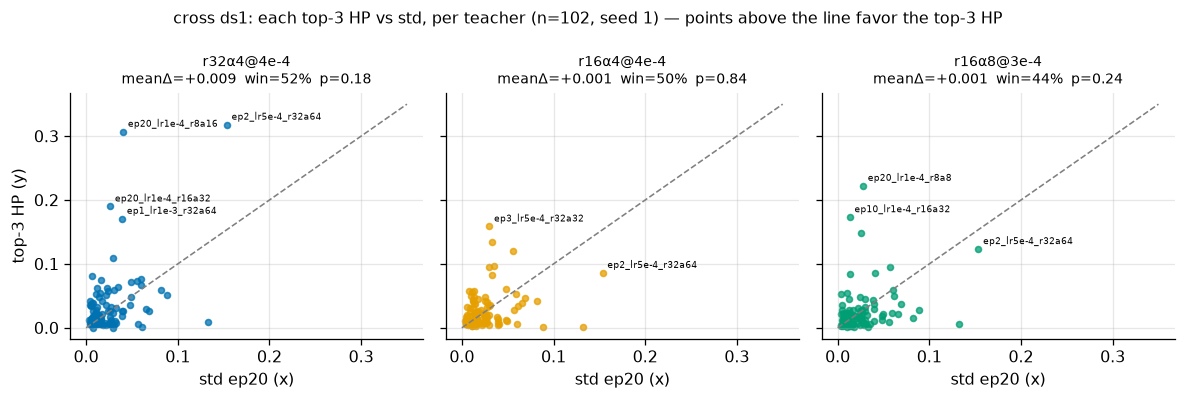

Spearman rank consistency of the TEACHER ordering (n per pair in parens):
  r32α4@4e-4 ~ r16α4@4e-4:  same-model +0.86 (102)   cross ds1 +0.24 (102)
  r32α4@4e-4 ~ r16α8@3e-4:  same-model +0.89 (102)   cross ds1 +0.24 (102)
  r16α4@4e-4 ~ r16α8@3e-4:  same-model +0.89 (102)   cross ds1 +0.06 (102)
same-model ~ cross ds1, same HP:
  r32α4@4e-4: +0.26 (n=102)
  r16α4@4e-4: +0.23 (n=102)
  r16α8@3e-4: +0.15 (n=102)
  same-model top-3 mean ~ cross std ep20: +0.49

focus teacher (ftseed1 values here vs the 5-seed means that picked these HPs):


base,cross ds1,same-model
variant,,
r32α4@4e-4,0.318,0.833
r16α4@4e-4,0.086,0.677
r16α8@3e-4,0.123,0.442
std r8α32@1e-4,0.153,0.956


In [5]:
cr = g14[g14.base.eq("cross ds1")].pivot_table(index="teacher_tag", columns="variant", values="test").dropna()
sm = g14[g14.base.eq("same-model")].pivot_table(index="teacher_tag", columns="variant", values="test").dropna()

fig, axs = plt.subplots(1, 3, figsize=(10.5, 3.5), sharex=True, sharey=True)
lim = 0.35
for ax, v in zip(axs, V_ORDER[:3]):
    # Points + y=x line via the shared helper; the per-teacher annotations and the
    # Wilcoxon title below stay this panel's own.
    aplots.identity_scatter(ax, cr, x=STD20[3], y=v, color=V_COLOR[v], s=14, alpha=0.75,
                            stat=None, title_stats=False, diag_lim=(0, lim))
    for tag in cr.index:
        if max(cr.loc[tag, STD20[3]], cr.loc[tag, v]) > 0.15:
            ax.annotate(tag, (cr.loc[tag, STD20[3]], cr.loc[tag, v]), fontsize=5.5,
                        xytext=(3, 3), textcoords="offset points")
    d = cr[v] - cr[STD20[3]]
    w = stats.wilcoxon(cr[v], cr[STD20[3]])
    ax.set_title(f"{v}\nmeanΔ={d.mean():+.3f}  win={(d > 0).mean():.0%}  p={w.pvalue:.2g}", fontsize=9)
    ax.set_xlabel(f"std ep20 (x)"); ax.set_ylabel("")   # shared y label set once below
axs[0].set_ylabel("top-3 HP (y)")
fig.suptitle(f"cross ds1: each top-3 HP vs std, per teacher (n={len(cr)}, seed 1) — points above the line favor the top-3 HP",
             fontsize=10)
plt.tight_layout(); plt.show()

print("Spearman rank consistency of the TEACHER ordering (n per pair in parens):")
pairs = list(it.combinations(V_ORDER[:3], 2))
for a, b in pairs:
    print(f"  {a} ~ {b}:  same-model {stats.spearmanr(sm[a], sm[b]).statistic:+.2f} ({len(sm)})"
          f"   cross ds1 {stats.spearmanr(cr[a], cr[b]).statistic:+.2f} ({len(cr)})")
both = g14.pivot_table(index="teacher_tag", columns=["base", "variant"], values="test").dropna(
    subset=[(b, v) for _, b in G14_BASES for v in V_ORDER[:3]])
print("same-model ~ cross ds1, same HP:")
for v in V_ORDER[:3]:
    r = stats.spearmanr(both[("same-model", v)], both[("cross ds1", v)])
    print(f"  {v}: {r.statistic:+.2f} (n={len(both)})")
r = stats.spearmanr(both["same-model"][V_ORDER[:3]].mean(axis=1), both[("cross ds1", STD20[3])])
print(f"  same-model top-3 mean ~ cross std ep20: {r.statistic:+.2f}")
print("\nfocus teacher (ftseed1 values here vs the 5-seed means that picked these HPs):")
display(g14[g14.teacher_tag.eq(FOCUS_TAG)].pivot_table(index="variant", columns="base", values="test")
        .reindex(V_ORDER).round(3))


## 4b. Is there a consensus cross-ranking under the noise? — yes, faint but real (added 2026-07-27)

The pairwise cross Spearman numbers above (ρ ≈ 0.1–0.3) say any *single* pair of HPs barely agrees on the
teacher ordering. But weak ≠ absent: if a shared "cross-distillable teacher" ordering exists under the eval
noise, it should get *stronger* when rankings are averaged — and pure floor noise shouldn't. Two tests:

- **Split-half consensus**: split the four student HPs (top-3 + std) 2+2, average each teacher's rank within
  each half, correlate the halves — all three splits. This is the honest version of "do different HP sets
  rank teachers similarly": each half is an independent 2-HP consensus.
- **Outlier robustness**: recompute the pairwise correlations after dropping every teacher with any cross
  cell ≥ 0.15, to check the agreement isn't just the few big outliers.

Below that: the **consensus table** (mean rank across the four HPs), which doubles as the candidate list for
per-teacher student-HP exploration — and, read row-wise, shows directly that **different teachers fire under
different student HPs** (each strong cell sits under a different column). Everything still seed 1: a
re-seeding pass on the top cells is the cheap confirmation step before building on any single row.


In [6]:
# Reuses cr (teacher x variant cross ds1 frame) from §4. Consensus = averaging ranks across student HPs.
import itertools as it

ranks = cr.rank(ascending=False)   # rank 1 = best cross transfer under that student HP
vs4 = list(cr.columns)
print(f"split-half consensus stability over n={len(cr)} teachers (avg rank of 2 HPs vs the other 2):")
for rest in it.combinations(vs4[1:], 1):        # the 3 unordered 2+2 splits all contain vs4[0] once
    half1 = [vs4[0], *rest]
    half2 = [v for v in vs4 if v not in half1]
    r = stats.spearmanr(ranks[half1].mean(axis=1), ranks[half2].mean(axis=1))
    print(f"  {half1} vs {half2}: rho={r.statistic:+.2f} (p={r.pvalue:.2g})")

out_tags = cr.index[(cr >= 0.15).any(axis=1)]
crd = cr.drop(out_tags)
print(f"\npairwise Spearman, full (n={len(cr)}) vs dropping the {len(out_tags)} outlier teachers (any cell >= 0.15):")
for a, b in it.combinations(vs4, 2):
    r1, r2 = stats.spearmanr(cr[a], cr[b]), stats.spearmanr(crd[a], crd[b])
    print(f"  {a} ~ {b}: {r1.statistic:+.2f} (p={r1.pvalue:.2g})  ->  {r2.statistic:+.2f} (p={r2.pvalue:.2g})")
print(f"  outliers: {sorted(out_tags)}")

cons = pd.DataFrame({"mean_rank": ranks.mean(axis=1), "max_p": cr.max(axis=1)}).join(cr).sort_values("mean_rank")
n10 = int((cr.max(axis=1) >= 0.10).sum())
print(f"\nconsensus top 12 (mean rank across the 4 student HPs); {n10} teachers reach max-over-HP >= 0.10:")
display(cons.head(12).round(3))


split-half consensus stability over n=102 teachers (avg rank of 2 HPs vs the other 2):
  ['r16α4@4e-4', 'r16α8@3e-4'] vs ['r32α4@4e-4', 'std r8α32@1e-4']: rho=+0.44 (p=3.3e-06)
  ['r16α4@4e-4', 'r32α4@4e-4'] vs ['r16α8@3e-4', 'std r8α32@1e-4']: rho=+0.30 (p=0.0022)
  ['r16α4@4e-4', 'std r8α32@1e-4'] vs ['r16α8@3e-4', 'r32α4@4e-4']: rho=+0.32 (p=0.00087)

pairwise Spearman, full (n=102) vs dropping the 7 outlier teachers (any cell >= 0.15):
  r16α4@4e-4 ~ r16α8@3e-4: +0.06 (p=0.52)  ->  +0.06 (p=0.56)
  r16α4@4e-4 ~ r32α4@4e-4: +0.24 (p=0.013)  ->  +0.28 (p=0.0061)
  r16α4@4e-4 ~ std r8α32@1e-4: +0.26 (p=0.0089)  ->  +0.27 (p=0.0078)
  r16α8@3e-4 ~ r32α4@4e-4: +0.24 (p=0.017)  ->  +0.14 (p=0.17)
  r16α8@3e-4 ~ std r8α32@1e-4: +0.26 (p=0.0085)  ->  +0.19 (p=0.067)
  r32α4@4e-4 ~ std r8α32@1e-4: +0.24 (p=0.016)  ->  +0.15 (p=0.15)
  outliers: ['ep10_lr1e-4_r16a32', 'ep1_lr1e-3_r32a64', 'ep20_lr1e-4_r16a32', 'ep20_lr1e-4_r8a16', 'ep20_lr1e-4_r8a8', 'ep2_lr5e-4_r32a64', 'ep3_lr5e-4_r32a32']

,mean_rank,max_p,r16α4@4e-4,r16α8@3e-4,r32α4@4e-4,std r8α32@1e-4
teacher_tag,,,,,,
ep2_lr5e-4_r32a64,3.00,0.318,0.086,0.123,0.318,0.153
ep10_lr1e-4_r8a32,12.25,0.110,0.096,0.046,0.110,0.030
ep20_lr1e-4_r32a32,15.00,0.076,0.053,0.023,0.076,0.059
ep3_lr5e-4_r32a32,15.00,0.159,0.159,0.033,0.060,0.030
ep20_lr1e-4_r8a32,19.25,0.069,0.046,0.037,0.026,0.069
ep20_lr1e-4_r8a8,21.50,0.222,0.041,0.222,0.032,0.028
ep7_lr2e-4_r8a32,23.25,0.082,0.042,0.016,0.059,0.082
ep5_lr5e-4_r8a16,23.50,0.149,0.049,0.149,0.026,0.026
ep7_lr5e-4_r8a8,24.00,0.120,0.120,0.008,0.074,0.056


## 5. Verdict: reading (b) — the HP gain was a lineage fluke; the bonus finding is same-model

*(single-seed values at the ~90/102 write-time snapshot — the numbers that moved after the drain + reseed are
flagged in the banner up top; the seed-averaged read is §14 of the source notebook)*

1. **The top-3 HPs do not generalize cross-init — reading (a) is dead.** On the ~90 non-focus teachers they
   are statistically indistinguishable from std at matched ep20: mean p_dog ≈ 0.026–0.035 vs std 0.024, win
   rates 46–54%, best Wilcoxon p = 0.055 (`r32α4@4e-4`, and its tiny +0.01 mean Δ is mostly two outlier
   teachers). The 75th percentile of the cross distribution is ≈ 0.03–0.04 for every HP — for most teachers
   cross-init transfer at ep20/seed-1 sits at the untrained-base floor (≈ 0.015–0.02 median), whatever the
   student HP. Student-HP choice is **not** the binding constraint on cross-init transfer; the teacher (and
   lineage) is. This closes the student-HP door from the aggressive end, as §10 of the source notebook closed
   it from the gentle end.
2. **The winner's curse, made concrete.** The focus lineage was the selected max of the top-6 probe, and the
   top-3 cells the selected max of a ~50-cell search on that lineage — shrinkage on re-test was the (b)
   prediction, and it happened. The gain is real *on the focus teacher* (`r32α4@4e-4`: 0.318 ftseed1, 5-seed
   mean 0.246, vs std 0.153 — the best cross cell in the whole grid) and lifts exactly one other teacher
   comparably (`ep20_lr1e-4_r8a16`, 0.31 vs std ≈ 0.05). Each HP's outliers are *different* teachers
   (`r16α4` → `ep3_lr5e-4_r32a32`; `r16α8` → `ep20_lr1e-4_r8a8`, `ep10_lr1e-4_r16a32`), and at seed 1 only
   `r32α4@4e-4` beats std on the very teacher the HPs were tuned on — the other two land below it.
3. **Bonus finding: same-model transfer is large and HP-robust.** Same numbers, same student HPs, only the
   init changes: mean ≈ 0.35–0.38, ~48% of teachers ≥ 0.3, ~33% ≥ 0.5 — versus ≈ 0.03 cross on the same
   teachers. This is the subliminal-learning signature at scale: the trait signal in the numbers is readable
   almost only by a student sharing the teacher's init. A hotter student amplifies a signal that exists
   same-model (all three HPs sit above the std@ep10 reference, 0.28 — epoch-confounded until the same-model
   std-ep20 backfill evals land) but cannot manufacture one cross-init.
4. **Teacher ranking is a stable object same-model; cross-init it is mostly — but not entirely — noise.**
   Between student HPs the teacher ordering agrees at Spearman ρ ≈ 0.86–0.89 same-model but only ≈ 0.1–0.3
   cross; per-HP same~cross agreement is ρ ≈ 0.1–0.2. However §4b's split-half test shows a **faint real
   consensus** under the cross noise (2-HP rank averages agree across halves at ρ ≈ 0.31–0.43, p ≤ 0.002),
   partially surviving outlier removal. "Distillable teacher" and "cross-transferring teacher" remain
   substantially different properties, and individual cross cells below ~0.1 still should not be interpreted.
5. **What this licenses next.** These four HPs cannot rule out that *other* teachers transfer under *other*
   student HPs — each teacher may have its own threshold, and the §4b table shows each strong cross cell
   fires under a **different** student HP (11 teachers reach max-over-HP ≥ 0.10). The supported next moves:
   (a) re-seed the strongest cross cells (they are all seed-1) to separate real responders from seed luck;
   (b) per-teacher student-HP exploration on the top §4b consensus teachers — the direct test of the
   per-teacher-threshold hypothesis; (c) the same-model std-ep20 backfill — landed 2026-07-28; §14's matched-ep20 read confirms #3's
   direction (top-3 beat std same-model, Δ +0.060–0.085).
